In [1]:
from II_funcs import *
from interp_funcs import *
plt.rcParams['mathtext.fontset'] =  "cm"
plt.rcParams['font.family'] =  "serif"
plt.rcParams['mathtext.default']='regular'

from scipy.interpolate import RegularGridInterpolator
from astropy import units as u
import pandas as pd

theta_E_1 = np.array([np.sqrt(4 * G * .1*(2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_2 = np.array([np.sqrt(4 * G * .2*(2e33) / c**2 * D_ls / (D_s * D_l))])

data=np.load('data/macro_lens_results.npz')
mag_fit=6.86
B_matrix=data['inv_jacobian_fit'][0]
phi_0=-2.07858699980682

In [2]:
import os
os.environ["PATH"] += ":/mnt/sw/nix/store/2h2mfxgy98zls6ja0czcz087i38v8wx3-texlive-20240312/bin/x86_64-linux"

from matplotlib import rc
rc("text", usetex=True)

In [3]:
from matplotlib import rc
from matplotlib import rcParams

rcParams['font.family'] = 'serif'
rc('text', usetex=True)
custom_preamble = {
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}"
    }
plt.rcParams.update(custom_preamble)


In [4]:
#define image specific constants, these don't change within this file
theta_max = 2e-10 # (half) size of image
image_size=8000  # BUGFIX: was 7000, but the gram_m02_10tE grids are 8000-pixel
                 # images (run_*.py hardcode image_size=8000); all m=0.1 map axes
                 # were previously compressed by 7000/8000 = 0.875.
N_step = image_size
beta_min = .9e-11
theta_step = 2 * theta_max / image_size
vec_theta = np.linspace(-theta_max, theta_max, N_step)
arr_theta = np.asarray(np.meshgrid(vec_theta, vec_theta, indexing='xy'))
g_params = (kappa_bulk, gamma1, gamma2)
rad = theta_500
rad_mas=rad*rad_to_arcsec
sigma_C = error_C(mag=15.76, wavelength=570e-7, R = 2e4, sigma_t=3e-12, A=10*(500**2)*np.pi, t_obs= 8 * 3600)

theta_step = 2 * (2e-10) / 8000
theta_step_mag = 2 * (1.5e-10) / 8000

Load in the data over the position grids for both masses

In [5]:
position_02_mag, fish_02_mag = load_mag_file('data/gram_m02_10tE_mag.txt')
position_02, rad_02, mass_02, xpos_02, ypos_02, cov_02 = load_file('data/gram_m02_10tE_II.txt')

# Rotate the (x, y) parameter block of every matrix into the shear-aligned frame of
# the grids (see shear_frame_matrix), so the reflection sign fixes in
# matrix_to_full/Jac_to_full are exact and the trajectory frame is consistent.
angle_rot = (-phi_0 + np.pi/2)
M2 = shear_frame_matrix(angle_rot)
S4 = np.eye(4); S4[2:, 2:] = M2

cov_combo_02 = []
rad_02_combo = []
mass_02_combo = []
posx_02_combo = []
posy_02_combo = []

for i in range(len(fish_02_mag)):
    mag_fisher = S4 @ np.asarray(fish_02_mag[i]) @ S4
    cov_fisher = S4 @ np.asarray(cov_02[i]) @ S4
    combo_cov, sigma_combo = get_combo_cov(mag_fisher, cov_fisher, theta_step_mag, theta_step, 1)
    cov_combo_02.append(combo_cov)
    rad_02_combo.append(sigma_combo[0])
    mass_02_combo.append(sigma_combo[1])
    posx_02_combo.append(sigma_combo[2])
    posy_02_combo.append(sigma_combo[3])

rad_02_combo=np.array(rad_02_combo)
mass_02_combo=np.array(mass_02_combo)
posx_02_combo=np.array(posx_02_combo)
posy_02_combo=np.array(posy_02_combo)

position_02_rad=position_02/8000
x_rot, y_rot = rotate_data_pos(position_02_rad.T[0], position_02_rad.T[1], angle_rot)
positions_rot = np.stack([(-np.abs(x_rot)).flatten(), (np.abs(y_rot)).flatten()], axis=1) * theta_step * image_size

In [6]:
chis_02_mag = load_chi2s('data/gram_m02_10tE_chi2_mag.txt')
chis_02_II = load_chi2s('data/gram_m02_10tE_chi2_II.txt')
chi_combo_02=chis_02_II+chis_02_mag
# 'centroids' holds the centroid Jacobian J[a, i]; cent0_grid holds the microlensed
# image centroid = the microlensing centroid shift Delta theta_c (radians).
pos_cent, centroids, cent0_grid = load_cents('data/gram_m02_10tE_cent.txt')
centroids=centroids.reshape(20,20,2,4)
# rotate centroid components and position parameters into the shear frame
centroids = np.einsum('ab,...bi,ij->...aj', M2, centroids, S4)
cent0_grid = cent0_grid.reshape(20,20,2)

Sigma_cent= np.einsum('...ia,...ab,...jb->...ij',  centroids*rad_to_arcsec, np.array(cov_combo_02).reshape(20,20,4,4), centroids*rad_to_arcsec)

sigma_x_tot = np.sqrt(np.abs(Sigma_cent[:,:,0, 0]))
sigma_y_tot = np.sqrt(np.abs(Sigma_cent[:,:,1, 1]))
cent_pres=np.sqrt(sigma_y_tot**2+sigma_x_tot**2)
# Metrics of Eqs. (21)-(22): sigma_1 = det(Sigma)^(1/4), sigma_2 = sqrt(lambda_min),
# both in uas.  (Previously det and lambda_min were plotted without the roots, i.e.
# uas^4 and uas^2 quantities on colorbars labelled uas.)
sigma_c1 = np.abs(np.linalg.det(Sigma_cent)).ravel()**0.25
sigma_c2 = np.sqrt(np.abs(np.min(np.linalg.eigvalsh(Sigma_cent.reshape(400, 2, 2)), axis=1)))

In [7]:
#define some constants for vel
bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

# Apparent (image-fixed-frame) proper-motion scales for the map annotations
# (see get_velocities): extremes along/perpendicular to the shear axis.
nu_unlensed = np.sqrt(bulk_vel**2+vel_disp**2)*1e5/((1+z_l)*D_l)*365.25*24*3600*rad_to_arcsec  # uas/yr
eigB = np.abs(np.linalg.eigvalsh(B_matrix))
mu_x = nu_unlensed*eigB.min()   # perpendicular to the shear axis (horizontal in plots)
mu_y = nu_unlensed*eigB.max()   # along the shear axis (vertical in plots)

In [8]:
no_lensing=get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), np.identity(2), z_l, D_l)
np.sqrt(no_lensing[0]**2+no_lensing[1]**2)*365*24*3600*rad_to_arcsec

np.float64(0.06888996157725295)

In [9]:
# Microlensing centroid shift |Delta theta_c| (uas) directly from the stored image
# centroids (the macro-only centroid vanishes by symmetry, so Delta theta_c = cent0).
# BUGFIX: this was previously approximated as 'centroids @ np.ones(4)' -- the sum of
# the Jacobian columns (the response to a unit change of ALL parameters at once),
# which is dimensionally inconsistent and is not the centroid shift.
dtheta = np.linalg.norm(cent0_grid, axis=-1) * rad_to_arcsec   # (20,20), uas

Sigma_inv = np.linalg.inv(Sigma_cent)  # (20,20,2,2)
prior_term = np.multiply((1 / dtheta**2)[..., None, None], np.eye(2))  # (20,20,2,2)
Sigma_res = np.linalg.inv(Sigma_inv + prior_term)

# residual metrics, Eqs. (21)-(22) applied to Sigma_res (uas)
sigma_c1_res = np.abs(np.linalg.det(Sigma_res)).ravel()**0.25
sigma_c2_res = np.sqrt(np.abs(np.min(np.linalg.eigvalsh(Sigma_res.reshape(400, 2, 2)), axis=1)))

### Corner plots

Code to generate corner plots similar to those in the paper

In [10]:
for i in range(len(mass_02_combo)):
    if mass_02_combo[i]>.09 and mass_02_combo[i]<.15  :#o[i]<1.5:
        print(i, mass_02_combo[i])

8 0.09181140327483017
30 0.11819982232064002
40 0.12685022909312293
41 0.12889837785007152
42 0.09779087914902986
44 0.10132359256811742
45 0.11516480183553143
61 0.12964310371882914
63 0.11210247348019563
64 0.12764667179999842


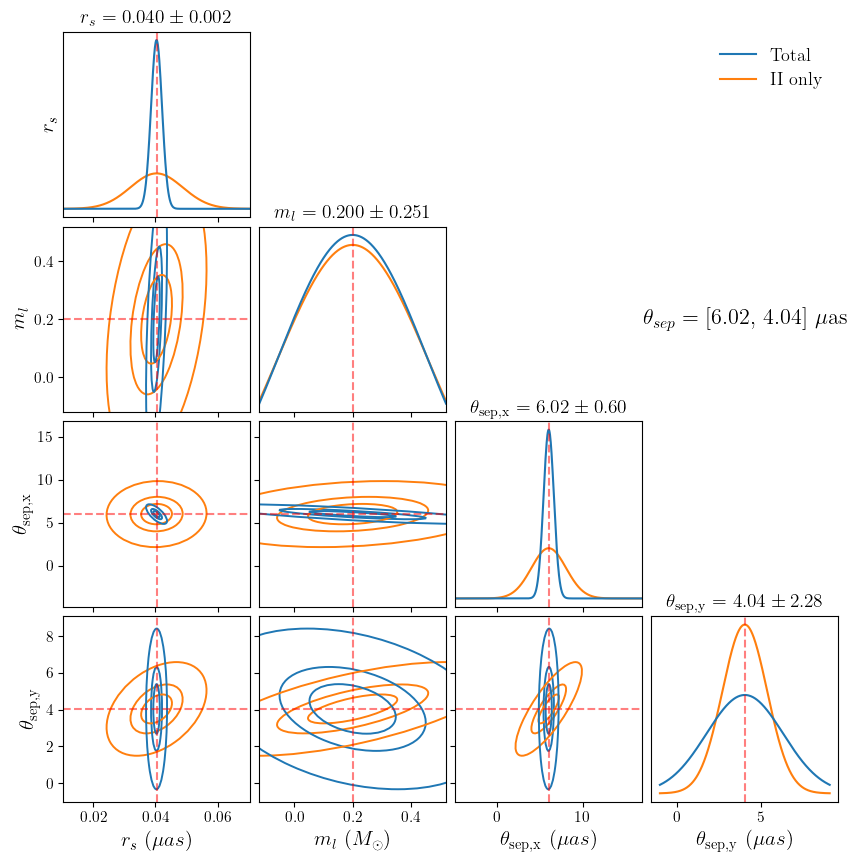

In [11]:
idx=32
pos_x_corner=(position_02[idx][0]-4000)*theta_step
pos_y_corner=(position_02[idx][1]-4000)*theta_step
mass_02_combo[idx]

titles = [r"$r_s\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_s$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.2, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.03, .32, 10.8, 5.05] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_02[idx] 
cov2 = cov_02[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

title=r'$\theta_{{sep}} = [$' + str(format(pos_x_corner*rad_to_arcsec, '.2f')) + ', ' + str(format(pos_y_corner*rad_to_arcsec, '.2f')) + r'$]\ \mu$as'
axes[1, -1].text(0.5, 0.5, title, fontsize=16, ha='center', va='center', transform=axes[1, -1].transAxes)
#plt.text(-25, 1.45, r'$\theta_{{sep}} = [-0.31,  0.57]\ \mu$as', fontsize=18);
#plt.show()

plt.savefig('figures/corner02_ell.pdf', bbox_inches='tight')
#FileLink('figures/corner02_res.pdf')

In [ ]:
idx=12
pos_x_corner=(position_02[idx][0]-4000)*theta_step
pos_y_corner=(position_02[idx][1]-4000)*theta_step
mass_02_combo[idx]

titles = [r"$r_s\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_s$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.2, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.03, .14, 3.6, 4.95] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_02[idx] 
cov2 = cov_02[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

title=r'$\theta_{{sep}} = [$' + str(format(pos_x_corner*rad_to_arcsec, '.2f')) + ', ' + str(format(pos_y_corner*rad_to_arcsec, '.2f')) + r'$]\ \mu$as'
axes[1, -1].text(0.5, 0.5, title, fontsize=16, ha='center', va='center', transform=axes[1, -1].transAxes)
#plt.text(-25, 1.45, r'$\theta_{{sep}} = [-0.31,  0.57]\ \mu$as', fontsize=18);
#plt.show()

plt.savefig('figures/corner02_res.pdf', bbox_inches='tight')
#FileLink('figures/corner02_res.pdf')

In [ ]:
idx=99
pos_x_corner=(position_02[idx][0]-4000)*theta_step
pos_y_corner=(position_02[idx][1]-4000)*theta_step
mass_02_combo[idx]

titles = [r"$r_s\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_s$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.2, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.05, 3.6, 51, 65.5] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_02[idx] 
cov2 = cov_02[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

title=r'$\theta_{{sep}} = [$' + str(format(pos_x_corner*rad_to_arcsec, '.2f')) + ', ' + str(format(pos_y_corner*rad_to_arcsec, '.2f')) + r'$]\ \mu$as'
axes[1, -1].text(0.5, 0.5, title, fontsize=16, ha='center', va='center', transform=axes[1, -1].transAxes)
#plt.show()

plt.savefig('figures/corner02_unres.pdf', bbox_inches='tight')
#FileLink('figures/corner02_unres.pdf')

### Interpolate errors

In [15]:
n = int(np.sqrt(len(x_rot)))

# build grid of points rotated by phi_0
x_grid = np.unique(positions_rot[:, 0].round(decimals=18))#*theta_step * image_size
x_grid = np.concat((x_grid, (-x_grid[len(x_grid)-2::-1])))
y_grid = np.unique(positions_rot[:, 1].round(decimals=15))#*theta_step * image_size
y_grid = np.concat((-y_grid[::-1], (y_grid[1:])))

rad_grid  = rad_02_combo.reshape(n, n)
mass_grid = mass_02_combo.reshape(n, n)
xpos_grid = posx_02_combo.reshape(n, n)
ypos_grid = posy_02_combo.reshape(n, n)


In [13]:
rad_grid  = one_quad_to_full(rad_02_combo, n)
mass_grid = one_quad_to_full(mass_02_combo, n)
xpos_grid = one_quad_to_full(posx_02_combo, n)
ypos_grid = one_quad_to_full(posy_02_combo, n)


In [14]:
# Build interpolators
rad_spline  = RegularGridInterpolator([x_grid, y_grid], rad_grid, method='linear')
mass_spline = RegularGridInterpolator([x_grid, y_grid], mass_grid, method='linear')
xpos_spline = RegularGridInterpolator([x_grid, y_grid], xpos_grid, method='linear') #takes position in radians, returns in mas
ypos_spline = RegularGridInterpolator([x_grid, y_grid], ypos_grid, method='linear')

In [15]:
# build fine grid to test these functions
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')


In [16]:
#evlulate on the dense grids for plotting
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
rad_interp = rad_spline(points).reshape(X_fine.shape)
mass_interp = mass_spline(points).reshape(X_fine.shape)
xpos_interp = xpos_spline(points).reshape(X_fine.shape)
ypos_interp = ypos_spline(points).reshape(X_fine.shape)

### Interpolate fisher matricies for m=0.1

In [17]:
# do this element wise, reshape back to a 4x4 grid at each point in the n x n grid
f_combo_02=[]
for i in range(len(cov_combo_02)):
    f_combo_02.append(np.linalg.inv(cov_combo_02[i]))
f_combo_02=np.array(f_combo_02)
f_combo_02 = f_combo_02.reshape(n, n, 4, 4)
f_combo_02  = matrix_to_full(f_combo_02, n)

In [18]:
#interpolate each element of the fisher matricies separately
interpolators = [[None for j in range(4)] for i in range(4)]

for i in range(4):
    for j in range(4):
        # Linear interpolation; 'bounds_error=False' allows extrapolation if needed
        interpolators[i][j] = RegularGridInterpolator(
            (x_grid, y_grid),
            f_combo_02[:, :, i, j], bounds_error=False, method='linear', fill_value=np.nan)
#build the function which will call each interpolator and put into a matrix
def fisher_interp_linear(pos):
    x, y = pos
    M = np.zeros((4, 4))
    for i in range(4):
        for j in range(4):
            M[i, j] = np.asarray(interpolators[i][j]([x, y])).ravel()[0]
    # enforce symmetry
    M = 0.5 * (M + M.T)
    return M

### Interpolate chi^2, J_cent

Same process as above, interpolate everything element wise if necessary, and build into a function. 

In [19]:
chi_grid  = one_quad_to_full(chi_combo_02, n)

fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)

chi_spline  = RegularGridInterpolator([x_grid, y_grid], chi_grid, bounds_error=False, method='linear', fill_value=np.nan)
chi_interp  = chi_spline(points).reshape(X_fine.shape)

In [20]:
chi_grid_II  = one_quad_to_full(chis_02_II, n)
chi_spline_II  = RegularGridInterpolator([x_grid, y_grid], chi_grid_II, bounds_error=False, method='linear', fill_value=np.nan)

chi_grid_mag  = one_quad_to_full(chis_02_mag, n)
chi_spline_mag  = RegularGridInterpolator([x_grid, y_grid], chi_grid_mag, bounds_error=False, method='linear', fill_value=np.nan)

In [21]:

centroids=centroids.reshape(n,n,2,4)
Jcent_grid  = Jac_to_full(centroids, n)

interpolators_cent=[[None for i in range(4)] for a in range(2)]

for a in range(2):        # centroid x/y
    for i in range(4):    # parameters
        interpolators_cent[a][i] = RegularGridInterpolator(
        (x_grid, y_grid),
        Jcent_grid[:, :, a, i], bounds_error=False, method='linear', fill_value=np.nan)

def Jcent_interp(pos):
    x, y = pos
    J = np.zeros((2, 4))
    for a in range(2):
        for i in range(4):
            J[a, i] = np.asarray(interpolators_cent[a][i]([x, y])).ravel()[0]
    return J

cent_pres  = one_quad_to_full(cent_pres, n)
cent_spline = RegularGridInterpolator([x_grid, y_grid], cent_pres, method='linear', fill_value=np.nan)
cent_interp = cent_spline(points).reshape(X_fine.shape)

sigma_c1  = one_quad_to_full(sigma_c1, n)
sigma_c1_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1, method='linear', fill_value=np.nan)
sigma_c1_interp = sigma_c1_spline(points).reshape(X_fine.shape)

sigma_c2  = one_quad_to_full(sigma_c2, n)
sigma_c2_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2, method='linear', fill_value=np.nan)
sigma_c2_interp = sigma_c2_spline(points).reshape(X_fine.shape)



In [22]:
sigma_c1_res  = one_quad_to_full(sigma_c1_res, n)
sigma_c1res_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1_res, method='linear', fill_value=np.nan)
sigma_c1res_interp = sigma_c1res_spline(points).reshape(X_fine.shape)

sigma_c2_res  = one_quad_to_full(sigma_c2_res, n)
sigma_c2res_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2_res, method='linear', fill_value=np.nan)
sigma_c2res_interp = sigma_c2res_spline(points).reshape(X_fine.shape)


In [23]:
sigma_c1_res.shape

(39, 39)

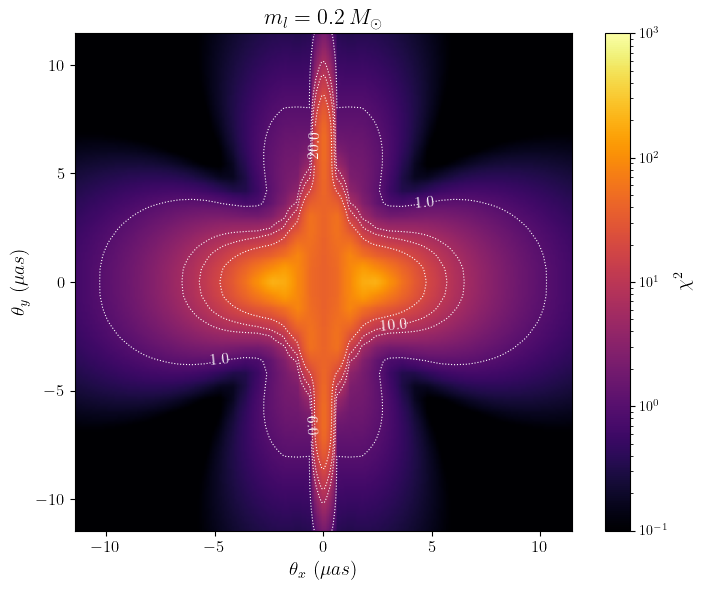

In [25]:
Z = np.flipud(chi_interp).T
X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

levels=[1, 6, 10, 20]
fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(Z, origin='lower', extent=extent, cmap='inferno', norm=matplotlib.colors.LogNorm(vmin=.1,vmax=1000),)
contours = ax.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax.clabel(contours, inline=True, fontsize=11, fmt="%.1f")

cbar = plt.colorbar(im, ax=ax, fraction=0.045, pad=.03)
cbar.set_label(r'$\chi^2$', fontsize=14)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='minor', labelsize=10)
plt.title(r'$m_l = 0.2 \, M_\odot$', fontsize=16)

ax.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('figures/chi02.pdf', bbox_inches='tight')


### Error Plots

Plots of the interpolated errors as evaluted on a finer grid of points

We see some numerical noise but within what we would expect to see

In [24]:
orig_map=plt.cm.get_cmap('cividis')

# reversing the original colormap using reversed() function
reversed_map = orig_map.reversed()

/tmp/ipykernel_4049128/603653901.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map=plt.cm.get_cmap('cividis')


In [ ]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6.6, 5.9))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = rad_mas/np.flipud(rad_interp).T

levels=[2, 5, 15]
im=ax1.imshow(Z, origin='lower', cmap=orig_map, extent=extent,
              norm=matplotlib.colors.LogNorm(vmin=1, vmax=30))
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
cbar.set_label(r'SNR $\ [r_s]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

#scale bar: 2 theta_E, same placement convention in all maps and masses
scale_length = float(np.ravel(2*theta_E_2*rad_to_arcsec)[0])  # scalar: text positions must not be arrays
x_start = np.min(fine_grid_x) - 4.2 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')
ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
plt.title(r'$m_l = 0.2 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('figures/rad_02.pdf')


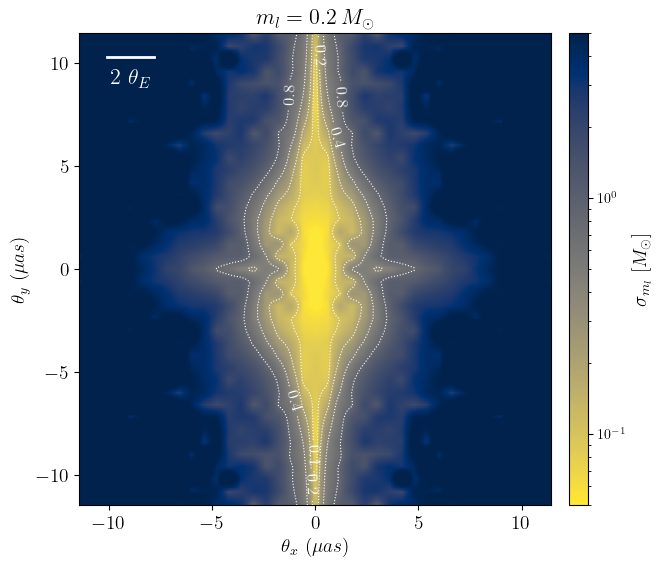

In [28]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(mass_interp).T

levels=[.1, .2, .4, .8]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, norm=matplotlib.colors.LogNorm(vmin=5e-2, vmax=5), extent=extent)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{m_l} \ [M_\odot]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.1f")

#scale bar: 2 theta_E, same placement convention in all maps and masses
scale_length = float(np.ravel(2*theta_E_2*rad_to_arcsec)[0])  # scalar: text positions must not be arrays
x_start = np.min(fine_grid_x) - 4.4 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=16,
         fontweight='black')
ax1.tick_params(axis='both', which='major', labelsize=14)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.2 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/mass_02.pdf')


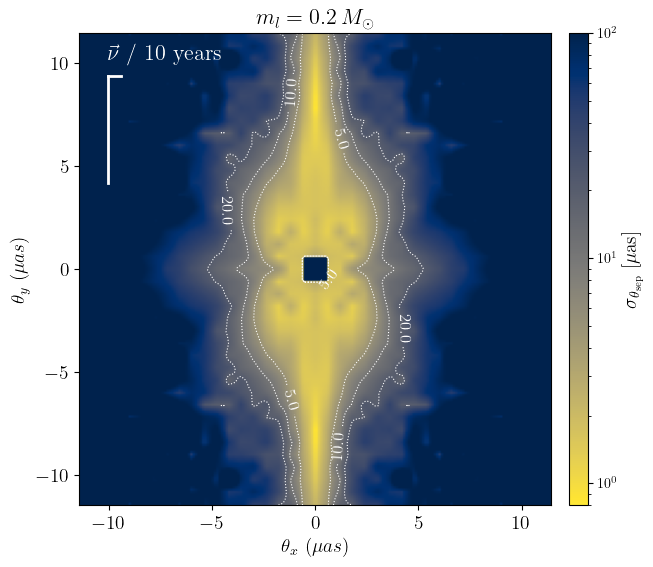

In [31]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.sqrt(np.flipud(xpos_interp).T**2+np.flipud(ypos_interp).T**2)

levels=[5, 10, 20]
im=ax1.imshow(Z, origin='lower',cmap=reversed_map,norm=matplotlib.colors.LogNorm(vmin=8e-1, vmax=1e2), extent=extent)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{\theta_{\rm sep}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.1f")

# proper-motion annotation (apparent nu x 10 yr along / perpendicular to the shear
# axis), anchored top-left at a fixed fraction of the map extent so its placement is
# identical across the four lens masses (the arrow lengths are physical, i.e.
# mass-independent).
scale_length_x=mu_x*10
scale_length_y=mu_y*10
x_start = 0.88*extent[0]
x_end = x_start + scale_length_x
y_pos = 0.82*extent[3]
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.plot([x_start, x_start], [y_pos-scale_length_y, y_pos], color='white', lw=2)
ax1.text(x_start, y_pos * 1.05, r"$\vec{\nu} \ / $ 10 years", color='white', ha='left', va='bottom', fontsize=16,
         fontweight='black')

ax1.tick_params(axis='both', which='major', labelsize=14)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.2 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)


plt.savefig('figures/pos_02.pdf')


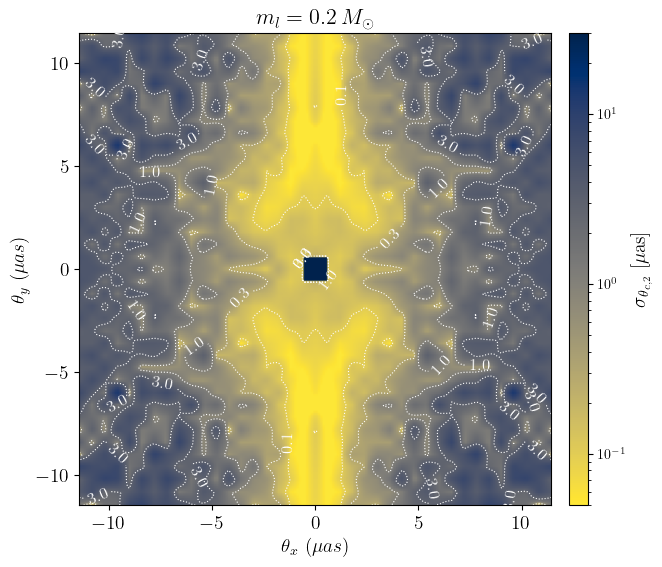

In [32]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2_interp).T

levels=[.1, .3, 1, 3]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=5e-2, vmax=3e1))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{\theta_{c,2}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.1f")

ax1.tick_params(axis='both', which='major', labelsize=14)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.2 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/thetac2_02.pdf')


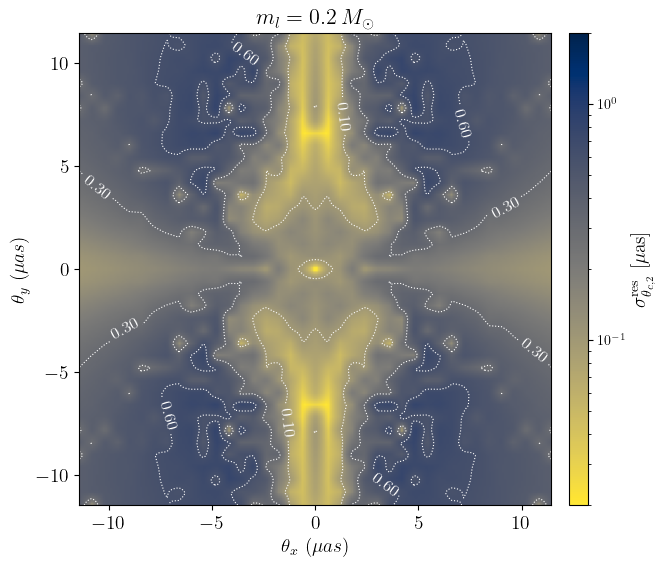

In [33]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2res_interp).T

levels=[.1, .3, .6]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=2e-2, vmax=2e0))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma^{\rm res}_{\theta_{c,2}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=14)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.2 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/thetac2res_02.pdf')


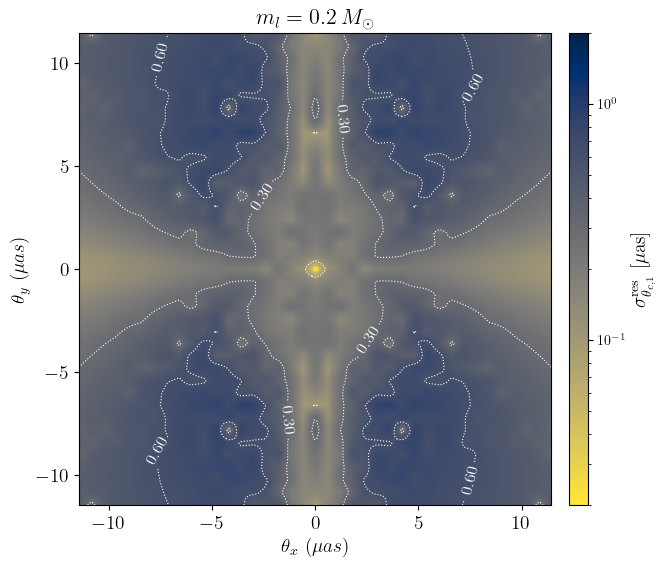

In [34]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1res_interp).T

levels=[.1, .3, .6]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=2e-2, vmax=2e0))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma^{\rm res}_{\theta_{c,1}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=14)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.2 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)


plt.savefig('figures/thetac1res_02.pdf')


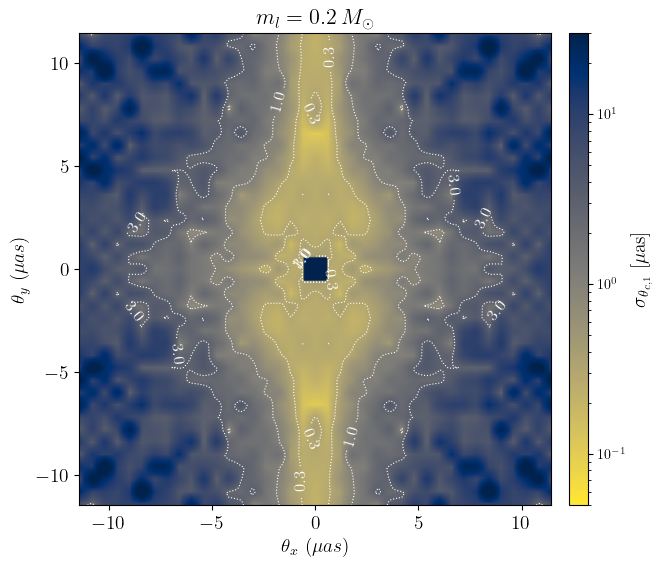

In [35]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1_interp).T

levels=[.1, .3, 1, 3]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=5e-2, vmax=3e1))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{\theta_{c,1}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.1f")

ax1.tick_params(axis='both', which='major', labelsize=14)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.2 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)


plt.savefig('figures/thetac1_02.pdf')


### Uncertainties as a function of min impact parameter

In [10]:
from II_funcs import *

In [11]:
def average_errors_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,chi_spline,dt_days=182.0,max_time_days=5*365.0,n_its=100,fisher_spline=fisher_interp_linear):

    fisher_thetas=[]
    cov_thetas=[]
    uncert_thetas=[]
    vels=[]
    chi_all=[]
    retries=[]
    Jcents=[]
    acc_covs=[]
    acc_sigmas=[]
    cent_cov_trajs=[]
    pos_trajs=[]
    time_trajs=[]

    for it in range(n_its):

        test_traj=sim_rand_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,dt_days=dt_days,max_time_days=max_time_days)

        positions_traj=test_traj['positions_rad']
        times_traj=test_traj['times_days']

        retry=0

        fisher_alpha=np.array([fisher_spline(p) for p in positions_traj])
        chi_traj=np.array([chi_spline(p) for p in positions_traj])
        centJ_traj=np.array([Jcent_interp(p) for p in positions_traj]).reshape(-1,2,4)

        fisher_theta_traj=f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24))
        cov_Theta,uncert_Theta=parameter_uncertainties(fisher_theta_traj,theta_step,printout=False,numstars=1)

        while np.any(np.isnan(uncert_Theta)):

            retry+=1

            test_traj=sim_rand_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,dt_days=dt_days,max_time_days=max_time_days)

            positions_traj=test_traj['positions_rad']
            times_traj=test_traj['times_days']

            fisher_alpha=np.array([fisher_spline(p) for p in positions_traj])
            chi_traj=np.array([chi_spline(p) for p in positions_traj])
            centJ_traj=np.array([Jcent_interp(p) for p in positions_traj]).reshape(-1,2,4)

            fisher_theta_traj=f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24))
            cov_Theta,uncert_Theta=parameter_uncertainties(fisher_theta_traj,theta_step,printout=False,numstars=1)

        retries.append(retry)

        pos_trajs.append(positions_traj)
        time_trajs.append(times_traj)
        vels.append(test_traj['velocity_kms'])

        chi_all.append(np.sum(chi_traj))

        C_alpha=np.linalg.inv(fisher_alpha)
        centroid_cov_traj=np.einsum('nij,njk,nlk->nil',centJ_traj,C_alpha,centJ_traj)

        cent_cov_trajs.append(centroid_cov_traj)

        acc_cov,sigma_acc=centroid_acceleration_uncertainty(centroid_cov_traj,times_traj)
        acc_covs.append(acc_cov)
        acc_sigmas.append(sigma_acc)

        Cinv_tot=np.sum(np.linalg.inv(centroid_cov_traj),axis=0)
        C_cent_tot=np.linalg.inv(Cinv_tot)
        Jcents.append(C_cent_tot)

        fisher_thetas.append(f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24)))

        cov_v_cm,cov_v_kms,sigma_v_kms=unlens_sigma_from_cov(cov_Theta,B_matrix,redshift,lens_dist)

        cov_Theta,uncert_Theta=parameter_uncertainties(fisher_thetas[-1],theta_step,printout=False,numstars=1)

        uncert_unlensed=np.array(uncert_Theta.copy())
        uncert_unlensed[4]=sigma_v_kms[0]*4.848136811e-12
        uncert_unlensed[5]=sigma_v_kms[1]*4.848136811e-12

        uncert_thetas.append(uncert_unlensed)

    cov_thetas=np.array(cov_thetas)
    Jcents=np.array(Jcents)
    chi_all=np.array(chi_all)

    cov_avg=np.mean(cov_thetas,axis=0)

    uncert_thetas=np.array(uncert_thetas)
    uncert_avg=np.sum(uncert_thetas,axis=0)/n_its

    vels=np.array(vels)

    return cov_thetas,cov_avg,uncert_thetas,uncert_avg,vels,chi_all,retries,Jcents,acc_sigmas,cent_cov_trajs,pos_trajs,time_trajs

NameError: name 'fisher_interp_linear' is not defined

In [28]:
impact_params = np.linspace(.3*theta_E_8[0], 5.9*theta_E_8[0], 40)[0:15]
impact_params/theta_E_8[0]

array([0.3       , 0.44358974, 0.58717949, 0.73076923, 0.87435897,
       1.01794872, 1.16153846, 1.30512821, 1.44871795, 1.59230769,
       1.73589744, 1.87948718, 2.02307692, 2.16666667, 2.31025641])

In [ ]:
# generate impact paramter array, use a 0.8 solar mass star so we can compare between stars how we do
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])

impact_params = np.linspace(.3*theta_E_8[0], 5.9*theta_E_8[0], 40)
impact_params=impact_params[0:27]  # extended: 0.2 detectable to ~3.6 theta_E,0.8 # no need to do all of them because the very distant points we have no hope
# of resolving for a lens this low mass (we can resolve them for the higher mass lenses)
chi_tots,uncert_avgs,n_retries=[],[],[]
chi_dists,uncert_dists=[],[]
cent_all,acc_sigmas=[],[]
traj_cov_cent=[]
pos_traj,time_traj=[],[]

for impact_param in impact_params:

    out=average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, np.max(x_grid), 8000, 
                            z_l, D_l, B_matrix, impact_param, chi_spline, fisher_spline=fisher_interp_linear, 
                            n_its=3000, dt_days=91.25, max_time_days=4*365.0)

    chi_tots.append(np.mean(out[5]))
    uncert_avgs.append(np.mean(out[2],axis=0))
    n_retries.append(out[6])

    chi_dists.append(out[5])
    uncert_dists.append(out[2])

    cent_all.append(out[9])
    acc_sigmas.append(out[8])
    traj_cov_cent.append(out[9])

    pos_traj.append(out[10])
    time_traj.append(out[11])

results = {
    "impact_params": impact_params,
    "chi_tots": np.array(chi_tots),
    "cent_all": np.array(cent_all),
    "uncert_avgs": np.array(uncert_avgs),
    "n_retried": np.array(n_retries),
    "chi_dists": np.array(chi_dists, dtype=object),
    "uncert_dists": np.array(uncert_dists, dtype=object),
    "acc_sigmas": np.array(acc_sigmas, dtype=object),
    "cent_traj": np.array(traj_cov_cent, dtype=object),
    "pos_traj": np.array(pos_traj, dtype=object),
    "time_traj": np.array(time_traj, dtype=object),
    }

filename = "avgs_02_8yr_cent.npz"
try:
    existing = np.load(filename, allow_pickle=True)

    combined = {}

    old_nimpact = len(existing["impact_params"])
    new_nimpact = len(impact_params)

    for key, new_vals in results.items():
        old_vals = existing[key]

        if key == "impact_params":
            combined[key] = np.hstack([old_vals, new_vals])

        elif key == "uncert_avgs":
            combined[key] = np.vstack([old_vals, new_vals])

        elif key in ["chi_tots"]:
            combined[key] = np.hstack([old_vals, new_vals])

        elif key in ["cent_all", "acc_sigmas", "cent_traj", "pos_traj", "time_traj", "chi_dists", "uncert_dists"]:
            combined[key] = np.hstack([old_vals, new_vals])

        elif key == "n_retried":
            combined[key] = np.hstack([old_vals, new_vals])

        else:
            combined[key] = np.hstack([old_vals, new_vals])

except FileNotFoundError:
    combined = results

np.savez(filename, **combined)

In [12]:
# load it back in
data = np.load("avgs_02_8yr_cent.npz", allow_pickle=True)

impact_params_all = data["impact_params"]
chi_all= data["chi_tots"]
uncert_all = data["uncert_avgs"]
chi_dists_all = data["chi_dists"]
uncert_dists_all = data["uncert_dists"] 

uniq = np.unique(impact_params_all)
chi_mean   = np.zeros(len(uniq))
uncert_mean = np.zeros((len(uniq), uncert_all.shape[1]))

for i, u in enumerate(uniq):
    mask = impact_params_all == u
    chi_mean[i]   = chi_all[mask].mean()
    uncert_mean[i] = uncert_all[mask].mean(axis=0)

impact_params = uniq
chi_full=np.array(chi_dists_all)
uncert_full=np.array(uncert_dists_all)

In [13]:
chi_full.shape

(27, 3000)

In [16]:
# |Delta theta_c| interpolant over the shear-frame grid (RADIANS), used to cap the
# per-epoch centroid covariance along trajectories (Eq. 24 of the paper).
dtheta_grid_rad = one_quad_to_full(np.linalg.norm(cent0_grid, axis=-1), n)
dtheta_spline = RegularGridInterpolator([x_grid, y_grid], dtheta_grid_rad,
                                        bounds_error=False, method='linear', fill_value=np.nan)

In [17]:
acc_sigmas=data["acc_sigmas"]
acc_arr = np.array(acc_sigmas.tolist(), dtype=np.float64)
acc_sigma_mag = np.linalg.norm(acc_arr, axis=-1)
acc_sigma_mean = acc_sigma_mag  # name kept for downstream cells
acc_sigma_84 = np.nanpercentile(acc_sigma_mag, 84, axis=-1)
acc_sigma_16 = np.nanpercentile(acc_sigma_mag, 16, axis=-1)
acc_sigma_50 = np.nanpercentile(acc_sigma_mag, 50, axis=-1)

cent_traj = data["cent_traj"]
times = data["time_traj"]
pos_traj = data["pos_traj"] #rad

pos = np.array(pos_traj, dtype=np.float64)
dtheta_traj = dtheta_spline(pos)


In [18]:
chunks = []

for i in range(len(cent_traj)):
    cent_res_i = apply_residual_cov_fast(
        np.array(cent_traj[i], dtype=np.float64),
        dtheta_traj[i])

    acc_i = acceleration_sigma_from_cov_traj_fast(
        cent_res_i[None],
        np.asarray(times[i:i+1], dtype=np.float64))

    chunks.append(acc_i[0])

acc_sigma_res = np.array(chunks)

In [19]:
cent_cov_res = apply_residual_cov_fast(np.array(cent_traj, dtype=np.float64), dtheta_traj)

acc_sigma_min_res2, acc_sigma_max_res2 = acceleration_sigma_from_cov_traj_eig(cent_cov_res, np.asarray(times, dtype=np.float64))
acc_sigma_res2 = acc_sigma_min_res2  

In [20]:
mag_acc_sig_r=np.linalg.norm(acc_sigma_res, axis=-1)
acc_sigma_res_50 = np.nanpercentile(mag_acc_sig_r, 50, axis=-1)
acc_sigma_res2_50 = np.nanpercentile(acc_sigma_res2, 50, axis=-1)


In [21]:
#check that all of these are in the area under chi^2=10, and they are!
n_retrys=data['n_retried']
cut=0
for i in range(len(n_retrys)):
    tries=np.sum(n_retrys[i])
    if tries>0:
        print("pos", np.array(impact_params/theta_E_8[0])[i], ':', tries)
    if np.percentile(chi_full, 50, axis=1)[i]<10 and cut==0:
        print('cutoff is ', np.array(impact_params/theta_E_8[0])[i])
        print('limit x axis to ', np.array(impact_params/theta_E_8[0])[i-1])
        xlim=np.array(impact_params/theta_E_8[0])[i-1]
        cut=10
        

cutoff is  4.0333333333333385
limit x axis to  3.8897435897435955


In [ ]:
p16= np.array(np.percentile(chi_full, 16, axis=1), dtype=float)
p84 = np.array(np.percentile(chi_full, 84, axis=1), dtype=float)
#xlim_real=1.2*xlim
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, np.percentile(chi_full, 50, axis=1), color='blue', label='Median')
ax.plot(impact_params / theta_E_8, chi_mean, label='Mean', color='red')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
#ax_top.set_xlim(0,xlim_real*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.axhspan(0,10, label='No microlensing evidence', alpha=.7, color='gray')
ax.set_ylabel(r'$\chi^2$', fontsize=13)
ax.set_xlabel(r'Min  $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_yscale('log')
#ax.set_xlim(.2, xlim_real)
ax.set_ylim(1, 1e4)
ax.legend(fontsize=13)
fig.tight_layout() # 5 years

In [ ]:
3.3.602564*impact_

#### Uncertainties 

In [22]:
# load in the averages
uncert_rads_avg =np.array(np.percentile(uncert_full[:,:,0], 50, axis=1))
uncert_mass_avg =np.array(np.percentile(uncert_full[:,:,1], 50, axis=1))
uncert_xpos_avg =np.array(np.percentile(uncert_full[:,:,2], 50, axis=1))
uncert_ypos_avg =np.array(np.percentile(uncert_full[:,:,3], 50, axis=1))
uncert_xvel_avg =np.array(np.percentile(uncert_full[:,:,4], 50, axis=1))
uncert_yvel_avg =np.array(np.percentile(uncert_full[:,:,5], 50, axis=1))
s_to_yr = 1 / (365.25 * 86400)  


In [23]:
import pandas


In [24]:
df=pd.DataFrame((np.array((impact_params/theta_E_8, uncert_rads_avg, uncert_mass_avg, 
                        uncert_xpos_avg, uncert_ypos_avg, uncert_xvel_avg, uncert_yvel_avg,
                        acc_sigma_50* rad_to_arcsec / s_to_yr**2, acc_sigma_res2_50*rad_to_arcsec / s_to_yr**2)).T),
                        columns=['impact_param', 'uncert_rad', 'uncert_mass', 'uncert_xpos', 'uncert_ypos', 'uncert_xvel', 'uncert_yvel', 
                                 'acc_sigma [mas/yr^2]', 'acc_sigma_res2 [mas/yr^2]'])

df

,impact_param,uncert_rad,uncert_mass,uncert_xpos,uncert_ypos,uncert_xvel,uncert_yvel,acc_sigma [mas/yr^2],acc_sigma_res2 [mas/yr^2]
0,0.3,0.000295,0.006227,0.04952,0.128886,131.207041,254.487432,0.02337,0.007307
1,0.44359,0.000288,0.006436,0.05138,0.112756,111.210799,223.515022,0.020629,0.007964
2,0.587179,0.000278,0.006645,0.056374,0.096887,97.286436,200.605745,0.018764,0.008178
3,0.730769,0.000287,0.006896,0.060236,0.09295,94.587046,179.401032,0.017882,0.007805
4,0.874359,0.000311,0.007238,0.064359,0.095562,97.051378,179.480383,0.01954,0.008417
5,1.017949,0.000337,0.008097,0.076632,0.105965,100.341444,187.201154,0.022161,0.008537
6,1.161538,0.000334,0.008478,0.0846,0.110256,100.943202,184.834692,0.025632,0.007647
7,1.305128,0.000324,0.008457,0.095811,0.105414,109.485501,190.82708,0.032182,0.006665
8,1.448718,0.00031,0.009917,0.11758,0.110311,124.304573,217.795621,0.034556,0.005685
9,1.592308,0.0003,0.012228,0.141649,0.118266,143.136593,262.774243,0.043343,0.005162


In [27]:
space=(impact_params[-1]-impact_params[-2])
impact_params_large=np.arange(6.61304348*theta_E_8[0], 9.5*theta_E_8[0], space)
impact_params_large[1:]/theta_E_8[0]

array([6.75663322, 6.90022297, 7.04381271, 7.18740245, 7.3309922 ,
       7.47458194, 7.61817169, 7.76176143, 7.90535117, 8.04894092,
       8.19253066, 8.3361204 , 8.47971015, 8.62329989, 8.76688963,
       8.91047938, 9.05406912, 9.19765886, 9.34124861, 9.48483835])

In [ ]:
p16 = np.array(np.percentile(uncert_full[:,:,0], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,0], 84, axis=1), dtype=float)
mean= np.array(np.mean(uncert_full[:,:,0], axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ylim=.0015
ax.plot(impact_params / theta_E_8, mean, label='Mean', color='red')
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,0], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ticks_top=np.linspace(theta_E_8[0]*rad_to_arcsec, 8*theta_E_8[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
ax_right.set_ylabel(r'$\sigma_{rs}$ ($r_s$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/rad_mas)

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14);
ax.set_ylabel(r"$\sigma_{rs}$ ($\mu$as)",  fontsize=14)
ax.set_xlim(.2, xlim)
#ax.set_ylim(0, ylim)

ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
p16 = np.array(np.percentile(uncert_full[:,:,1], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,1], 84, axis=1), dtype=float)
mean=np.array(np.mean(uncert_full[:,:,1], axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))
ax.plot(impact_params / theta_E_8, mean,  label='Mean', color='red')
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,1], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)
ax.axhline(0.1, linestyle='dashed', color='gray')


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [m_l]\ \ (M_0)$", fontsize=14)
ax.set_xlim(.2, xlim)
#ax.set_ylim(0, .22)
ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
p16 = np.array(np.percentile(uncert_full[:,:,2], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,2], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,2], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ylim=1.1
ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [\theta_{\text{sep},x}]$  ($\theta_{E, 0.2}$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [\theta_{\text{sep},x}]$ ($\mu$as)", fontsize=14)
ax.legend()
ax.set_xlim(.2, xlim)

ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
dist_uncert=(np.array(uncert_full[:,:,2])**2+np.array(uncert_full[:,:,3])**2)**(0.5)
p16 = np.array(np.percentile(dist_uncert, 16, axis=1), dtype=float)
p84= np.array(np.percentile(dist_uncert, 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, (impact_params/theta_E_8)/np.percentile(dist_uncert, 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, (impact_params/theta_E_8)/p16, (impact_params/theta_E_8)/p84,  alpha=0.8, label='16–84% range', color='lightblue')
ylim=2.5
ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [|\theta_{\text{sep}}|]$  ($\theta_{E, 0.2}$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [|\theta_{\text{sep}}|]$ ($\mu$as)", fontsize=14)
ax.legend()
ax.set_xlim(.2, xlim)
ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
(.3**2+.4**2)**(.5)

In [ ]:
p16 = np.array(np.percentile(uncert_full[:,:,3], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,3], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))
ylim=2.5

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,3], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [\theta_{\text{sep},y}]$  ($\theta_{E, 0.2}$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [\theta_{\text{sep},y}]$ ($\mu$as)", fontsize=14)
ax.set_xlim(.2, xlim)

ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
p16 = np.array(np.percentile(uncert_full[:,:,4], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,4], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) #actual here has mean around 400 km/s and std 207.2 km/s
ylim=5.1

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,4], 50, axis=1),color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, x}$ (km/s)", fontsize=14)
#plt.xlim(0.4, 2.5)
ax.set_xlim(.2, xlim)

ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
# mean 0 and std 181.4 km/s
p16 = np.array(np.percentile(uncert_full[:,:,5], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,5], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,5], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, y}$ (km/s)", fontsize=14)
ax.set_xlim(.2, xlim)

#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
# mean 0 and std 181.4 km/s
p16 = sigma_cent1_16*rad_to_arcsec**4
p84 = sigma_cent1_84*rad_to_arcsec**4

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, sigma_cent1_50*rad_to_arcsec**4, color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{|c|, 1}$ (mu as)", fontsize=14)
ax.set_xlim(.2, xlim)

#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
# mean 0 and std 181.4 km/s
p16 = sigma_cent2_16*rad_to_arcsec**2
p84 = sigma_cent2_84*rad_to_arcsec**2

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, sigma_cent2_50*rad_to_arcsec**2, color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{|c|, 2}$ (mu as)", fontsize=14)
ax.set_xlim(.2, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()